# RiboGRAM 1.0.0 — complete inference test

This notebook is an executable, hierarchical smoke test for every inference
path released in `infer.py`. It covers:

1. the three base models (`RiboGRAM`, `PLM-CDS`, and `PLM-mRNA`);
2. sequence embeddings;
3. attention extraction for the CD-box, tRNA, and H/ACA-box manuscript cases;
4. the 13-class and 88-class ncRNA heads;
5. RPI, RPIplus, RRI, and RCI prediction.

Classification and interaction inputs are **real labelled records** copied from
the original evaluation datasets. Their identifiers, labels, splits, dataset
paths, and reference scripts are preserved in `test_samples.json`. These
individual examples validate the inference path; they are not substitutes for
a full benchmark.


## 1. Runtime and file hierarchy

### 1.1 Imports, device, and output directories

Run the notebook from the directory containing `infer.py`. Outputs are written
to a task-based hierarchy under `test_outputs/`.


In [1]:
from pathlib import Path
import gc
import json
import math
import platform
import subprocess
import sys

import matplotlib.pyplot as plt
import torch

from infer import (
    ATTENTION_CASES,
    DEFAULT_EMBEDDING_SEQUENCES,
    inference_attention_batch,
    inference_interaction,
    inference_ncrna13,
    inference_ncrna88,
    inference_sequence_embeddings,
)

ROOT = Path.cwd().resolve()
if not (ROOT / "infer.py").is_file():
    raise RuntimeError("Start Jupyter in the directory containing infer.py")

CHECKPOINT_DIR = ROOT / "checkpoints"
OUTPUT_DIR = ROOT / "test_outputs"
SAMPLE_FILE = ROOT / "test_samples.json"
REAL_SAMPLES = json.loads(SAMPLE_FILE.read_text(encoding="utf-8"))
for subdirectory in ("embeddings", "attention", "classification", "interaction"):
    (OUTPUT_DIR / subdirectory).mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEST_STATUS = {}

runtime = {
    "RiboGRAM_version": "1.0.0",
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "CUDA_available": torch.cuda.is_available(),
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "output_directory": "test_outputs",
}
print(json.dumps(runtime, indent=2))


{
  "RiboGRAM_version": "1.0.0",
  "Python": "3.8.18",
  "PyTorch": "1.13.1+cu116",
  "CUDA_available": true,
  "device": "NVIDIA A100-SXM4-40GB",
  "output_directory": "test_outputs"
}


### 1.2 Checkpoint inventory

The minimal package contains `RiboGRAM.pkl`, `ribogram_ncrna13_head.pt`, and `ribogram_ncrna88_head.pt`. Download any additional task-specific checkpoint from [the official RiboGRAM page](https://www.ultrarnalab.com/ribogram.php) and place it in `checkpoints/`. Missing optional models are reported as `SKIP`; the filenames below are the canonical names used by the CLI and Python API.


In [2]:
CHECKPOINTS = {
    "RiboGRAM": CHECKPOINT_DIR / "RiboGRAM.pkl",
    "PLM-CDS": CHECKPOINT_DIR / "PLM-CDS.pkl",
    "PLM-mRNA": CHECKPOINT_DIR / "PLM-mRNA.pkl",
    "RiboGRAM-RPI": CHECKPOINT_DIR / "RiboGRAM-RPI.pkl",
    "RiboGRAM-RPIplus": CHECKPOINT_DIR / "RiboGRAM-RPI_plus.pkl",
    "RiboGRAM-RRI": CHECKPOINT_DIR / "RiboGRAM-RRI.pkl",
    "RiboGRAM-RCI": CHECKPOINT_DIR / "RiboGRAM-RCI.pkl",
    "ncRNA13-head": CHECKPOINT_DIR / "ribogram_ncrna13_head.pt",
    "ncRNA88-head": CHECKPOINT_DIR / "ribogram_ncrna88_head.pt",
}

for name, path in CHECKPOINTS.items():
    state = "OK" if path.is_file() else "MISSING"
    size = f"{path.stat().st_size / 1024**3:.3f} GiB" if path.is_file() else "-"
    print(f"{name:28s} {state:7s} {size}")


RiboGRAM                     OK      3.157 GiB
PLM-CDS                      OK      3.157 GiB
PLM-mRNA                     OK      3.157 GiB
RiboGRAM-RPI                 OK      3.158 GiB
RiboGRAM-RPIplus             OK      3.158 GiB
RiboGRAM-RRI                 OK      3.158 GiB
RiboGRAM-RCI                 OK      3.158 GiB
ncRNA13-head                 OK      0.043 GiB
ncRNA88-head                 OK      0.058 GiB


### 1.3 CLI task hierarchy

The notebook uses the Python API so that tensors can be inspected directly.
The same tasks are exposed through the following CLI hierarchy.


In [3]:
help_text = subprocess.run(
    [sys.executable, str(ROOT / "infer.py"), "--help"],
    check=True,
    capture_output=True,
    text=True,
).stdout
print(help_text)


usage: infer.py [-h] {embedding,attention,ncrna13,ncrna88,interaction} ...

Unified inference examples for the RiboGRAM model family. The module exposes
reusable Python functions and a small command-line interface for sequence
embeddings, attention maps, ncRNA-13/ncRNA-88 classification, and the
RPI/RPIplus/RRI/RCI interaction tasks.

positional arguments:
  {embedding,attention,ncrna13,ncrna88,interaction}
    embedding           Extract RNA embeddings
    attention           Calculate RNA attention
    ncrna13             Classify 13 ncRNA categories
    ncrna88             Classify 88 Rfam families
    interaction         Predict RPI/RPIplus/RRI/RCI interactions

optional arguments:
  -h, --help            show this help message and exit



### 1.4 Shared reporting helpers

Embedding tensors are saved to disk, while their exact output dimensions are printed in the notebook. Attention tests display matrix dimensions and retain only the final composite figure under `test_outputs/attention/`.


In [4]:
def one_based_position_ticks(length, max_ticks=8):
    """Map zero-based matrix coordinates to one-based sequence labels."""
    raw_step = max(1.0, length / max_ticks)
    magnitude = 10 ** math.floor(math.log10(raw_step))
    step = next(
        int(multiplier * magnitude)
        for multiplier in (1, 2, 5, 10)
        if multiplier * magnitude >= raw_step
    )
    labels = [1, *range(step, length + 1, step)]
    if labels[-1] != length:
        labels.append(length)
    labels = list(dict.fromkeys(labels))
    return [label - 1 for label in labels], labels


def release_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def save_json(data, relative_path):
    path = OUTPUT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    return path


def embedding_summary(results):
    return [
        {
            "label": item["label"],
            "sequence_length": len(item["sequence"]),
            "layer": item["layer"],
            "token_embeddings_shape": list(item["token_embeddings"].shape),
            "mean_embedding_shape": list(item["mean_embedding"].shape),
        }
        for item in results
    ]


def attention_summary(results):
    return {
        item["label"]: {
            "sequence_length": len(item["sequence"]),
            "layer": item["layer"],
            "head": item["head"],
            "num_heads": item["num_heads"],
            "per_head_shape": list(item["per_head_attention"].shape),
            "selected_head_shape": list(item["head_attention"].shape),
            "mean_shape": list(item["mean_attention"].shape),
            "apc_shape": list(item["apc_attention"].shape),
            "apc_min": float(item["apc_attention"].min()),
            "apc_max": float(item["apc_attention"].max()),
            "apc_mean": float(item["apc_attention"].mean()),
        }
        for item in results
    }


def save_embedding_test(architecture, filename):
    checkpoint = CHECKPOINTS[architecture]
    status_key = f"embedding/{architecture}"
    if not checkpoint.is_file():
        TEST_STATUS[status_key] = f"SKIP (download {checkpoint.name})"
        print(TEST_STATUS[status_key])
        return

    results = inference_sequence_embeddings(
        checkpoint,
        DEFAULT_EMBEDDING_SEQUENCES,
        architecture=architecture,
        layer=12,
        device=DEVICE,
    )
    path = OUTPUT_DIR / "embeddings" / filename
    torch.save(results, path)
    summary = embedding_summary(results)
    del results
    release_memory()
    TEST_STATUS[status_key] = "PASS"
    print(f"Saved: {path.relative_to(ROOT)}")
    for item in summary:
        print(
            f"{architecture}/{item['label']}: "
            f"token_embeddings={tuple(item['token_embeddings_shape'])}, "
            f"mean_embedding={tuple(item['mean_embedding_shape'])}"
        )


def save_interaction_test(name, checkpoint, architecture, sample):
    status_key = f"interaction/{name}"
    if not checkpoint.is_file():
        TEST_STATUS[status_key] = f"SKIP (download {checkpoint.name})"
        print(TEST_STATUS[status_key])
        return

    result = inference_interaction(
        checkpoint,
        architecture,
        [(sample["id"], sample["rna"], sample["partner"])],
        device=DEVICE,
    )[0]
    label_match = result["prediction"] == sample["expected_label"]
    artifact = {
        "sample": sample,
        "prediction": result,
        "label_match": label_match,
    }
    path = save_json(artifact, f"interaction/{name}.json")
    release_memory()
    if not label_match:
        raise AssertionError(
            f"{name}: expected {sample['expected_label']}, "
            f"predicted {result['prediction']}"
        )
    TEST_STATUS[status_key] = "PASS"
    print(json.dumps({"saved": str(path.relative_to(ROOT)), **artifact}, indent=2))


## 2. Base-model sequence embeddings

The output for each RNA contains a token matrix of shape
`[sequence_length, 1280]` and a mean vector of shape `[1280]`. Special tokens
and padding are excluded.

### 2.1 Test inputs


In [5]:
for label, sequence in DEFAULT_EMBEDDING_SEQUENCES:
    print(f"{label}: length={len(sequence)} nt")


RNA_sequence_1: length=88 nt
RNA_sequence_2: length=88 nt


### 2.2 RiboGRAM embeddings


In [6]:
save_embedding_test("RiboGRAM", "RiboGRAM_embeddings.pt")


Saved: test_outputs/embeddings/RiboGRAM_embeddings.pt
RiboGRAM/RNA_sequence_1: token_embeddings=(88, 1280), mean_embedding=(1280,)
RiboGRAM/RNA_sequence_2: token_embeddings=(88, 1280), mean_embedding=(1280,)


### 2.3 PLM-CDS embeddings


In [7]:
save_embedding_test("PLM-CDS", "PLM-CDS_embeddings.pt")


Saved: test_outputs/embeddings/PLM-CDS_embeddings.pt
PLM-CDS/RNA_sequence_1: token_embeddings=(88, 1280), mean_embedding=(1280,)
PLM-CDS/RNA_sequence_2: token_embeddings=(88, 1280), mean_embedding=(1280,)


### 2.4 PLM-mRNA embeddings


In [8]:
save_embedding_test("PLM-mRNA", "PLM-mRNA_embeddings.pt")


Saved: test_outputs/embeddings/PLM-mRNA_embeddings.pt
PLM-mRNA/RNA_sequence_1: token_embeddings=(88, 1280), mean_embedding=(1280,)
PLM-mRNA/RNA_sequence_2: token_embeddings=(88, 1280), mean_embedding=(1280,)


## 3. Attention extraction

Each result retains all Layer-12 heads (`20 × L × L`) and their mean. The displayed and APC-adjusted matrix is the **final attention head (Head 20)**, matching the manuscript analysis scripts. The examples below remove special tokens, symmetrize the selected head, and retain positive APC values.

### 3.1 RiboGRAM manuscript cases: CD-box, tRNA, and H/ACA-box


In [9]:
attention_inputs = [(case.name, case.sequence) for case in ATTENTION_CASES.values()]
ribogram_attention = inference_attention_batch(
    CHECKPOINTS["RiboGRAM"],
    attention_inputs,
    architecture="RiboGRAM",
    layer=12,
    head=20,
    device=DEVICE,
    symmetrize=True,
    positive_apc=True,
)

print(json.dumps(attention_summary(ribogram_attention), indent=2))
TEST_STATUS["attention/RiboGRAM-manuscript-cases"] = "PASS"
release_memory()


{
  "CD-box_snoZ39": {
    "sequence_length": 60,
    "layer": 12,
    "head": 20,
    "num_heads": 20,
    "per_head_shape": [
      20,
      60,
      60
    ],
    "selected_head_shape": [
      60,
      60
    ],
    "mean_shape": [
      60,
      60
    ],
    "apc_shape": [
      60,
      60
    ],
    "apc_min": 0.0,
    "apc_max": 0.8629432320594788,
    "apc_mean": 0.01081793662160635
  },
  "tRNA": {
    "sequence_length": 76,
    "layer": 12,
    "head": 20,
    "num_heads": 20,
    "per_head_shape": [
      20,
      76,
      76
    ],
    "selected_head_shape": [
      76,
      76
    ],
    "mean_shape": [
      76,
      76
    ],
    "apc_shape": [
      76,
      76
    ],
    "apc_min": 0.0,
    "apc_max": 0.9641634821891785,
    "apc_mean": 0.009521790780127048
  },
  "HACA-box_snoF1_F2": {
    "sequence_length": 140,
    "layer": 12,
    "head": 20,
    "num_heads": 20,
    "per_head_shape": [
      20,
      140,
      140
    ],
    "selected_head_shape": [


### 3.2 APC attention heatmaps

These plots visualize Layer 12, Head 20 after symmetric averaging and positive-only APC. The manuscript style uses Matplotlib's `magma` colour map: zero is black, intermediate signal is purple/magenta, and the strongest signal is yellow-white. Only this three-case composite is saved; the notebook does not duplicate every matrix as PT, CSV, JSON, and PNG files.


Saved: test_outputs/attention/RiboGRAM_manuscript_cases.png


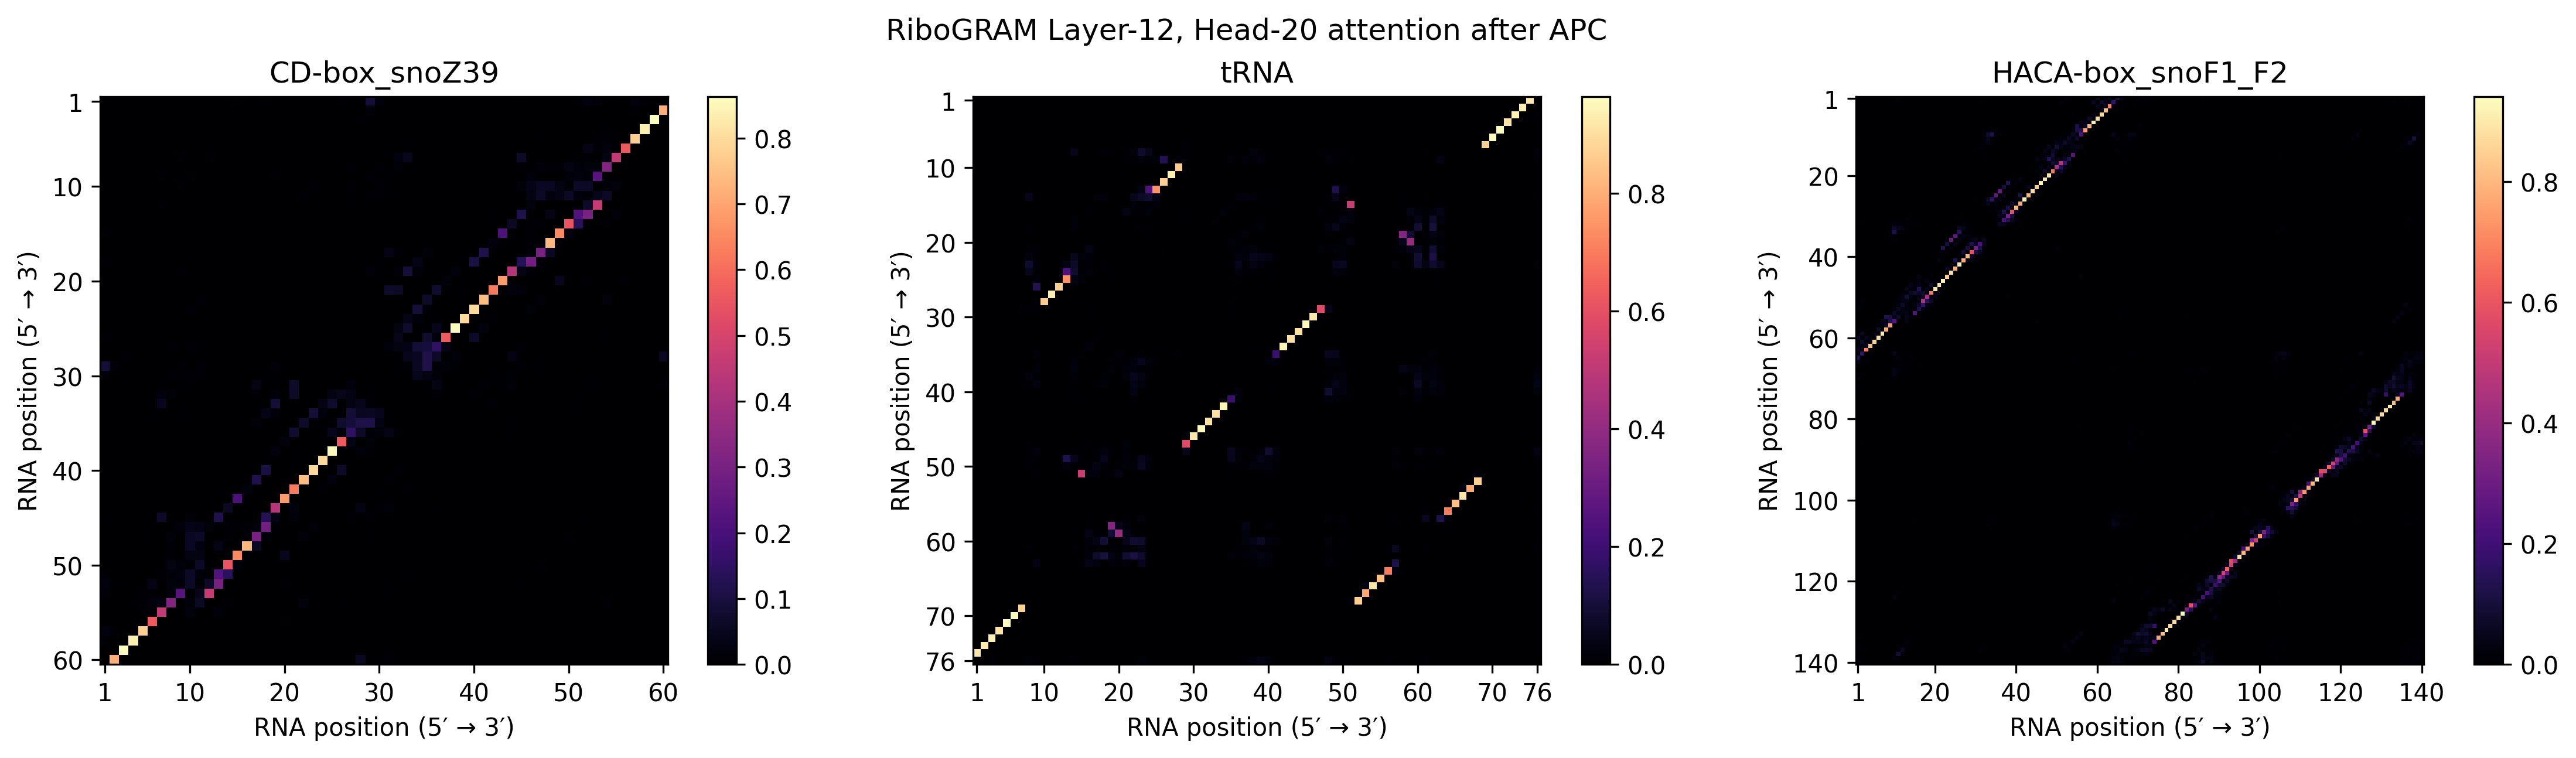

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for axis, result in zip(axes, ribogram_attention):
    matrix = result["apc_attention"].numpy()
    length = matrix.shape[0]
    tick_positions, tick_labels = one_based_position_ticks(length)
    image = axis.imshow(
        matrix,
        cmap="magma",
        interpolation="nearest",
        origin="upper",
        vmin=0.0,
    )
    axis.set_xticks(tick_positions, tick_labels)
    axis.set_yticks(tick_positions, tick_labels)
    axis.set_xlim(-0.5, length - 0.5)
    axis.set_ylim(length - 0.5, -0.5)
    axis.set_title(result["label"])
    axis.set_xlabel("RNA position (5′ → 3′)")
    axis.set_ylabel("RNA position (5′ → 3′)")
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
figure.suptitle("RiboGRAM Layer-12, Head-20 attention after APC")
composite_path = OUTPUT_DIR / "attention" / "RiboGRAM_manuscript_cases.png"
figure.savefig(composite_path, dpi=300, bbox_inches="tight")
print(f"Saved: {composite_path.relative_to(ROOT)}")


## 4. ncRNA classification

Both classifiers freeze the RiboGRAM backbone and consume pooled Layer-12
features. Each example is a real record from the corresponding official test
split. The saved JSON contains sample provenance, expected label, complete
probability dictionary, prediction, and label-match result.

### 4.1 Real classification inputs and provenance


In [11]:
NCRNA13_SAMPLE = REAL_SAMPLES["classification"]["ncRNA13"]
NCRNA88_SAMPLE = REAL_SAMPLES["classification"]["ncRNA88"]

for task, sample in (("ncRNA13", NCRNA13_SAMPLE), ("ncRNA88", NCRNA88_SAMPLE)):
    print(json.dumps({
        "task": task,
        "id": sample["id"],
        "length": len(sample["sequence"]),
        "expected_label": sample["expected_label"],
        "split": sample["split"],
        "source_dataset": sample["source_dataset"],
        "reference_script": sample["reference_script"],
    }, indent=2))


{
  "task": "ncRNA13",
  "id": "JNOY01098855.1/3507-3580",
  "length": 74,
  "expected_label": "tRNA",
  "split": "test",
  "source_dataset": "ncRNA_dataset.csv",
  "reference_script": "20251010_function_ncRNA_RibonTrans_probing_layer12.py"
}
{
  "task": "ncRNA88",
  "id": "RF00005",
  "length": 62,
  "expected_label": "RF00005",
  "split": "Test",
  "source_dataset": "ncRNA_88category.txt",
  "reference_script": "20250929_function_ncRNA88_RibonTrans_probing.py"
}


### 4.2 Thirteen-category ncRNA classification


In [12]:
ncrna13_prediction = inference_ncrna13(
    CHECKPOINTS["RiboGRAM"],
    CHECKPOINTS["ncRNA13-head"],
    [(NCRNA13_SAMPLE["id"], NCRNA13_SAMPLE["sequence"])],
    device=DEVICE,
)[0]
ncrna13_artifact = {
    "sample": NCRNA13_SAMPLE,
    "prediction": ncrna13_prediction,
    "label_match": ncrna13_prediction["predicted_label"] == NCRNA13_SAMPLE["expected_label"],
}
path = save_json(ncrna13_artifact, "classification/ncRNA13.json")
if not ncrna13_artifact["label_match"]:
    raise AssertionError("ncRNA13 prediction does not match the recorded test label")
print(json.dumps({"saved": str(path.relative_to(ROOT)), **ncrna13_artifact}, indent=2))
TEST_STATUS["classification/ncRNA13"] = "PASS"
release_memory()


{
  "saved": "test_outputs/classification/ncRNA13.json",
  "sample": {
    "id": "JNOY01098855.1/3507-3580",
    "sequence": "GUUUCUGUAGUGUAGUGGUUAUCAUAUUUGCCUCACAUGCAUAAGAUCCCUGGUUUGUAACUGGGCAGACAACA",
    "expected_label": "tRNA",
    "expected_label_id": 4,
    "split": "test",
    "source_dataset": "ncRNA_dataset.csv",
    "source_path_original": "/share/project/wanghui/0000/downstream_datasets/ncRNA_classifi/ncRNA_dataset.csv",
    "reference_script": "20251010_function_ncRNA_RibonTrans_probing_layer12.py",
    "selection": "first tRNA record in the official test split"
  },
  "prediction": {
    "id": "JNOY01098855.1/3507-3580",
    "sequence": "GUUUCUGUAGUGUAGUGGUUAUCAUAUUUGCCUCACAUGCAUAAGAUCCCUGGUUUGUAACUGGGCAGACAACA",
    "num_classes": 13,
    "predicted_label_id": 4,
    "predicted_label": "tRNA",
    "confidence": 0.9912766218185425,
    "probabilities": {
      "5S-rRNA": 0.0006868100608699024,
      "CD-box": 0.0006684113759547472,
      "Riboswitch": 0.000649189576506614

### 4.3 Eighty-eight-family ncRNA classification


In [13]:
ncrna88_prediction = inference_ncrna88(
    CHECKPOINTS["RiboGRAM"],
    CHECKPOINTS["ncRNA88-head"],
    [(NCRNA88_SAMPLE["id"], NCRNA88_SAMPLE["sequence"])],
    device=DEVICE,
)[0]
ncrna88_artifact = {
    "sample": NCRNA88_SAMPLE,
    "prediction": ncrna88_prediction,
    "label_match": ncrna88_prediction["predicted_label"] == NCRNA88_SAMPLE["expected_label"],
}
path = save_json(ncrna88_artifact, "classification/ncRNA88.json")
if not ncrna88_artifact["label_match"]:
    raise AssertionError("ncRNA88 prediction does not match the recorded test label")
print(json.dumps({"saved": str(path.relative_to(ROOT)), **ncrna88_artifact}, indent=2))
TEST_STATUS["classification/ncRNA88"] = "PASS"
release_memory()


{
  "saved": "test_outputs/classification/ncRNA88.json",
  "sample": {
    "id": "RF00005",
    "sequence": "UGGUGGUUCAGUGGUAGAAUUCUCACCUUUCAGGUGGAAGACCCAGGUUCAAUUCCCGGCCA",
    "expected_label": "RF00005",
    "expected_label_id": 4,
    "split": "Test",
    "source_dataset": "ncRNA_88category.txt",
    "source_path_original": "/share/project/wanghui/0000/downstream_datasets/ncRNA_classifi/ncRNA_88category.txt",
    "reference_script": "20250929_function_ncRNA88_RibonTrans_probing.py",
    "selection": "first RF00005 record in the official Test split"
  },
  "prediction": {
    "id": "RF00005",
    "sequence": "UGGUGGUUCAGUGGUAGAAUUCUCACCUUUCAGGUGGAAGACCCAGGUUCAAUUCCCGGCCA",
    "num_classes": 88,
    "predicted_label_id": 4,
    "predicted_label": "RF00005",
    "confidence": 0.9921000599861145,
    "probabilities": {
      "RF00001": 6.44630563328974e-05,
      "RF00002": 6.867109186714515e-05,
      "RF00003": 0.00010044332884717733,
      "RF00004": 9.296074858866632e-05,
      "R

## 5. Interaction models

Every example below is a real labelled record from the dataset used by the
corresponding task. Saved JSON files contain the original sample metadata,
expected label, normalized model input, logit, probability, prediction, and
label-match result. A PASS means successful inference and agreement for this
single example; it is not an aggregate performance estimate.

### 5.1 Real interaction inputs and provenance


In [14]:
RPI_SAMPLE = REAL_SAMPLES["interaction"]["rpi"]
RRI_SAMPLE = REAL_SAMPLES["interaction"]["rri"]
RCI_SAMPLE = REAL_SAMPLES["interaction"]["rci"]

for task, sample in (("RPI/RPIplus", RPI_SAMPLE), ("RRI", RRI_SAMPLE), ("RCI", RCI_SAMPLE)):
    print(json.dumps({
        "task": task,
        "id": sample["id"],
        "rna_length": len(sample["rna"]),
        "partner_length": len(sample["partner"]),
        "expected_label": sample["expected_label"],
        "split": sample["split"],
        "source_dataset": sample["source_dataset"],
        "reference_script": sample["reference_script"],
    }, indent=2))


{
  "task": "RPI/RPIplus",
  "id": "chr15_96282877_96282978_-_AARS_K562",
  "rna_length": 101,
  "partner_length": 500,
  "expected_label": 1,
  "split": "test",
  "source_dataset": "AARS_K562.csv and rbp2bed_seq_20260807_138.txt",
  "reference_script": "202501207_DDP_STAR_pretraining_add_CNN_beforeAddBias_long_short_Protein_20260107_withBCEloss_ultra_top10w_add_before.py"
}
{
  "task": "RRI",
  "id": "r1=chrX:12977034-12977082(+)_r2=chrM:9015-9075(+)",
  "rna_length": 49,
  "partner_length": 61,
  "expected_label": 1,
  "split": "80%-identity held-out test",
  "source_dataset": "20260127_type15_seq_low_500_test_data_positive_negative80.csv",
  "reference_script": "202501207_DDP_STAR_pretraining_add_CNN_beforeAddBias_long_short_RNA_20260129RASP_withBCEloss_15type_new.py"
}
{
  "task": "RCI",
  "id": "chr22_48496015_48496081_+__chr22_48495959_48496059",
  "rna_length": 67,
  "partner_length": 101,
  "expected_label": 1,
  "split": "validation",
  "source_dataset": "20260119_HEK293T_RNA_

### 5.2 RiboGRAM-RPI


In [15]:
save_interaction_test(
    "RiboGRAM-RPI",
    CHECKPOINTS["RiboGRAM-RPI"],
    "RiboGRAM-RPI",
    RPI_SAMPLE,
)


{
  "saved": "test_outputs/interaction/RiboGRAM-RPI.json",
  "sample": {
    "id": "chr15_96282877_96282978_-_AARS_K562",
    "rna": "CCAGCACAGUGUCAUGGGACAGUGGGCCCUGGUGCCACAAUGCCCGGCAUCUCCACCAGAUACAGCUUUGAGAUCUUCAUGAUGAAGCUUGCUCCAAUCCA",
    "partner": "MDSTLTASEIRQRFIDFFKRNEHTYVHSSATIPLDDPTLLFANAGMNQFKPIFLNTIDPSHPMAKLSRAANTQKCIRAGGKHNDLDDVGKDVYHHTFFEMLGSWSFGDYFKELACKMALELLTQEFGIPIERLYVTYFGGDEAAGLEADLECKQIWQNLGLDDTKILPGNMKDNFWEMGDTGPCGPCSEIHYDRIGGRDAAHLVNQDDPNVLEIWNLVFIQYNREADGILKPLPKKSIDTGMGLERLVSVLQNKMSNYDTDLFVPYFEAIQKGTGARPYTGKVGAEDADGIDMAYRVLADHARTITVALADGGRPDNTGRGYVLRRILRRAVRYAHEKLNASRGFFATLVDVVVQSLGDAFPELKKDPDMVKDIINEEEVQFLKTLSRGRRILDRKIQSLGDSKTIPGDTAWLLYDTYGFPVDLTGLIAEEKGLVVDMDGFEEERKLAQLKSQGKGAGGEDLIMLDIYAIEELRARGLEVTDDSPKYNYHLDSSGSYVFE",
    "partner_name": "AARS",
    "expected_label": 1,
    "split": "test",
    "source_dataset": "AARS_K562.csv and rbp2bed_seq_20260807_138.txt",
    "source_path_original": "/share/project/wanghui/STAR/20251222/20260106_RBP/20260807/k563_10w/

### 5.3 RiboGRAM-RPIplus


In [16]:
save_interaction_test(
    "RiboGRAM-RPI_plus",
    CHECKPOINTS["RiboGRAM-RPIplus"],
    "RiboGRAM-RPIplus",
    RPI_SAMPLE,
)


{
  "saved": "test_outputs/interaction/RiboGRAM-RPI_plus.json",
  "sample": {
    "id": "chr15_96282877_96282978_-_AARS_K562",
    "rna": "CCAGCACAGUGUCAUGGGACAGUGGGCCCUGGUGCCACAAUGCCCGGCAUCUCCACCAGAUACAGCUUUGAGAUCUUCAUGAUGAAGCUUGCUCCAAUCCA",
    "partner": "MDSTLTASEIRQRFIDFFKRNEHTYVHSSATIPLDDPTLLFANAGMNQFKPIFLNTIDPSHPMAKLSRAANTQKCIRAGGKHNDLDDVGKDVYHHTFFEMLGSWSFGDYFKELACKMALELLTQEFGIPIERLYVTYFGGDEAAGLEADLECKQIWQNLGLDDTKILPGNMKDNFWEMGDTGPCGPCSEIHYDRIGGRDAAHLVNQDDPNVLEIWNLVFIQYNREADGILKPLPKKSIDTGMGLERLVSVLQNKMSNYDTDLFVPYFEAIQKGTGARPYTGKVGAEDADGIDMAYRVLADHARTITVALADGGRPDNTGRGYVLRRILRRAVRYAHEKLNASRGFFATLVDVVVQSLGDAFPELKKDPDMVKDIINEEEVQFLKTLSRGRRILDRKIQSLGDSKTIPGDTAWLLYDTYGFPVDLTGLIAEEKGLVVDMDGFEEERKLAQLKSQGKGAGGEDLIMLDIYAIEELRARGLEVTDDSPKYNYHLDSSGSYVFE",
    "partner_name": "AARS",
    "expected_label": 1,
    "split": "test",
    "source_dataset": "AARS_K562.csv and rbp2bed_seq_20260807_138.txt",
    "source_path_original": "/share/project/wanghui/STAR/20251222/20260106_RBP/20260807/k563

### 5.4 RiboGRAM-RRI

In [17]:
save_interaction_test(
    "RiboGRAM-RRI",
    CHECKPOINTS["RiboGRAM-RRI"],
    "RiboGRAM-RRI",
    RRI_SAMPLE,
)


{
  "saved": "test_outputs/interaction/RiboGRAM-RRI.json",
  "sample": {
    "id": "r1=chrX:12977034-12977082(+)_r2=chrM:9015-9075(+)",
    "rna": "GGTGAAGGAAGAAGTGGGGTGGAAGAAGTGGGGTGGGACGACAGTGAAA",
    "partner": "CATTACTGCAGGCCACCTACTCATGCACCTAATTGGAAGCGCCACCCTAGCAATATCAACC",
    "rna1_id": "r1=chrX:12977034-12977082(+)",
    "rna2_id": "r2=chrM:9015-9075(+)",
    "interaction_type": "protein_coding-protein_coding",
    "expected_label": 1,
    "split": "80%-identity held-out test",
    "source_dataset": "20260127_type15_seq_low_500_test_data_positive_negative80.csv",
    "source_path_original": "/share/project/wanghui/STAR/20251222/RNA_data/20260127_type15_seq_low_500_test_data_positive_negative80.csv",
    "reference_script": "202501207_DDP_STAR_pretraining_add_CNN_beforeAddBias_long_short_RNA_20260129RASP_withBCEloss_15type_new.py",
    "selection": "labelled positive record from the official 80%-identity test set"
  },
  "prediction": {
    "id": "r1=chrX:12977034-12977082(+)_r2

### 5.5 RiboGRAM-RCI

In [18]:
save_interaction_test(
    "RiboGRAM-RCI",
    CHECKPOINTS["RiboGRAM-RCI"],
    "RiboGRAM-RCI",
    RCI_SAMPLE,
)


{
  "saved": "test_outputs/interaction/RiboGRAM-RCI.json",
  "sample": {
    "id": "chr22_48496015_48496081_+__chr22_48495959_48496059",
    "rna": "GCUCCUAUCGCCCGUGAAGGCCCGGCUUACUCCCUAAAUGCAGUGGAUGCAGGAAGGCAUGGUGAGC",
    "partner": "GCTGCTTGTGCTCATTCCTCTCCCACATACTCCGGATTGGACATAGGTGCTGTGGTGCTCCTATCGCCCGTGAAGGCCCGGCTTACTCCCTAAATGCAGTG",
    "rna_id": "chr22_48496015_48496081_+",
    "dna_id": "chr22_48495959_48496059",
    "score": 1.05,
    "expected_label": 1,
    "split": "validation",
    "source_dataset": "20260119_HEK293T_RNA_DNA_sample500w_validation_set.csv",
    "source_path_original": "/share/project/wanghui/STAR/20251222/20260119_DNA/20260119_HEK293T_RNA_DNA_sample500w_validation_set.csv",
    "reference_script": "202501207_DDP_STAR_pretraining_add_CNN_beforeAddBias_long_short_DNA_20260120_withBCEloss_HEK293T.py",
    "selection": "first labelled positive record in the official HEK293T validation set"
  },
  "prediction": {
    "id": "chr22_48496015_48496081_+__chr22_4849595

## 6. Final validation summary

A successful complete run reports `PASS` for every inference path. For the
classification and interaction examples, PASS also requires agreement with the
recorded dataset label.


In [19]:
print("TEST STATUS")
for task, state in TEST_STATUS.items():
    print(f"{state:24s} {task}")

print("\nOUTPUT FILE HIERARCHY")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        size = path.stat().st_size
        print(f"{path.relative_to(ROOT)}  ({size:,} bytes)")

failed = [task for task, state in TEST_STATUS.items() if state != "PASS" and not state.startswith("SKIP")]
if failed:
    raise RuntimeError(f"Failed tasks: {failed}")
print("\nAll available inference paths completed successfully.")


TEST STATUS
PASS                     embedding/RiboGRAM
PASS                     embedding/PLM-CDS
PASS                     embedding/PLM-mRNA
PASS                     attention/RiboGRAM-manuscript-cases
PASS                     classification/ncRNA13
PASS                     classification/ncRNA88
PASS                     interaction/RiboGRAM-RPI
PASS                     interaction/RiboGRAM-RPI_plus
PASS                     interaction/RiboGRAM-RRI
PASS                     interaction/RiboGRAM-RCI

OUTPUT FILE HIERARCHY
test_outputs/attention/RiboGRAM_manuscript_cases.png  (200,356 bytes)
test_outputs/classification/ncRNA13.json  (1,387 bytes)
test_outputs/classification/ncRNA88.json  (4,336 bytes)
test_outputs/embeddings/PLM-CDS_embeddings.pt  (913,249 bytes)
test_outputs/embeddings/PLM-mRNA_embeddings.pt  (913,255 bytes)
test_outputs/embeddings/RiboGRAM_embeddings.pt  (913,255 bytes)
test_outputs/interaction/RiboGRAM-RCI.json  (1,336 bytes)
test_outputs/interaction/RiboGRAM-RPI.jso